# DiffusionRegPose: diffusion, decoder geometry and image attention

Inspect **32 fixed CrowdPose test images** using the saved **reduced OTA epoch-79
model**, at **1, 2 and 3 diffusion steps**. The checkpoint has **three decoder
layers**: a box-only stage, followed by two joint-refinement stages. They were
initialized from ED-Pose layers 2/4/6; the notebook labels their executed order 1/2/3.

Each diffusion step runs the whole model, including all three decoder layers.
Only joint XY proposals are diffusion variables. Incoming decoder references,
predicted joints and image-attention sampling points are different quantities
and are shown in separate figures/panels.

**Selection:** a seeded random sample without replacement from test images with
labeled noncrowd people, followed by a fixed image order. Each image starts with
identical Gaussian proposals at S=1/2/3 (`proposal_seed + image_id`); DDIM eta=0.
The three best/worst **images** are ranked separately for each S by per-image
keypoint AP: standard CrowdPose OKS thresholds .50:.95 and 101 recall positions,
after native pose NMS, with image ID breaking ties. Empty predictions score zero;
undefined scores are excluded and counted. The same images can be compared across S.

**Scope:** these are 32-image diagnostics from one checkpoint and one proposal
seed. Subset AP is not full-test AP, and mean per-image AP differs from subset AP.
All native detections enter evaluation; the gallery confidence cutoff is visual only.

In [1]:
from pathlib import Path
import os
import sys

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / 'AGENTS.md').exists() and (path / 'src').is_dir())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT)) if str(ROOT) not in sys.path else None
(ROOT / 'tmp').mkdir(exist_ok=True)
os.environ['TMPDIR'] = str(ROOT / 'tmp')

import matplotlib.pyplot as plt
import pandas as pd
import torch
from omegaconf import OmegaConf
from IPython import get_ipython
from IPython.display import display, Markdown
get_ipython().run_line_magic('matplotlib', 'inline')
from scripts.investigation.diffusionregpose_inspection.run import (
    DEFAULT_RUN, Settings, run_inspection, load_trace,
)
from scripts.investigation.diffusionregpose_inspection.plots import (
    JOINT_NAMES, gallery_figure, geometry_figure, proposal_figure,
    mask_figure, attention_figure, person_attention_figure,
)

# Keep the checkpoint and resolved architecture configuration paired.
settings = Settings(
    checkpoint=DEFAULT_RUN + '/checkpoints/epoch079.ckpt',
    config=DEFAULT_RUN + '/.hydra/config.yaml',
    sample_count=32, subset_seed=42, proposal_seed=1729,
    shortest_side=256, max_size=427, steps=(1, 2, 3),
    output='tmp/diffusionregpose_diffusion_inspection',
    device='cuda' if torch.cuda.is_available() else 'cpu',
)
FORCE_RERUN = False
DISPLAY_SCORE_THRESHOLD = .25
FIGURES = Path(settings.output) / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
print('Repository:', ROOT)
print('Device:', settings.device)

Repository: /home/gasparyanartur/dev/pose-graph-diff
Device: cuda


## Run or reload the inspection

The first run strictly restores the saved weights, evaluates the same 32 images
at all three step counts, and traces the union of the best/worst images at all S.
Later runs reuse the cache only when checkpoint, configuration, annotations,
source hashes, settings and PyTorch version match. Traces live under local `tmp/`.
No model or training code is modified. A fresh checkout needs the saved checkpoint,
its resolved config, CrowdPose data and the project's configured Python environment.

In [2]:
cache = run_inspection(settings, force=FORCE_RERUN)
provenance = {
    'checkpoint': settings.checkpoint, 'checkpoint_sha256': cache['manifest']['checkpoint_sha256'],
    'config': settings.config, 'epoch (zero-based)': cache['epoch'],
    'split': settings.annotations, 'coverage': f"{len(cache['image_ids'])} test images",
    'resize': f'{settings.shortest_side}/{settings.max_size}, aspect-preserving PIL + ImageNet normalization',
    'training matcher': OmegaConf.load(settings.config).pipeline.get('matching_strategy', 'hungarian'),
    'sampling': 'native deterministic DDIM, eta=0',
    'proposal seed': f'{settings.proposal_seed} + image_id, reset per S',
    'subset seed': settings.subset_seed, 'decoder layers': cache['decoder_layers'],
    'native CUDA attention loaded': cache['native_cuda_kernel_loaded'],
    'PyTorch': cache['manifest']['torch_version'],
    'evaluation': 'crowdposetools COCOeval keypoints / bbox; native pose NMS',
}
display(pd.DataFrame(provenance.items(), columns=['Field', 'Value']))
print('Ordered image IDs:', cache['image_ids'])
print('Replay checks:', cache['verification'])

Loaded verified matching inspection cache.


,Field,Value
0,checkpoint,results/diffusionregpose_development_compatibl...
1,checkpoint_sha256,97ee195be5f944f3cea424eb188a310277bc0bdee529e8...
2,config,results/diffusionregpose_development_compatibl...
3,epoch (zero-based),79
4,split,data/crowdpose/annotations/crowdpose_test.json
5,coverage,32 test images
6,resize,"256/427, aspect-preserving PIL + ImageNet norm..."
7,training matcher,ota
8,sampling,"native deterministic DDIM, eta=0"
9,proposal seed,"1729 + image_id, reset per S"


Ordered image IDs: [112913, 102260, 100498, 115050, 105637, 105052, 104571, 102840, 114956, 102109, 113687, 115025, 118250, 111057, 101788, 111935, 108518, 100656, 100606, 101920, 104488, 104771, 110222, 112161, 100537, 111369, 104043, 114552, 113125, 114242, 111053, 108465]
Replay checks: {'selected_replay_exact': True, 'evaluated_settings': 96}


## Performance on the fixed subset

Subset AP pools detections across the 32 images. Per-image AP evaluates each image
separately with the same evaluator; it determines the galleries below. Neither
score uses ground-truth-derived initial proposals. No person is rematched to a
favorable prediction to choose the best/worst images.

,AP,bbox/AP
diffusion_steps,,
1,0.505718,0.477583
2,0.507381,0.477054
3,0.504237,0.478515


,AP_S1,AP_S2,AP_S3,S2_minus_S1,S3_minus_S1
image_id,,,,,
111057,1.000000,1.000000,1.000000,0.000000,0.000000
115025,1.000000,1.000000,1.000000,0.000000,0.000000
112913,0.925248,0.925248,0.925248,0.000000,0.000000
100537,0.925248,0.925248,0.925248,0.000000,0.000000
114552,0.925248,0.925248,0.925248,0.000000,0.000000
111053,0.900990,0.900990,0.900990,0.000000,0.000000
111935,0.900990,0.900990,0.900990,0.000000,0.000000
108465,0.900990,0.900990,0.900990,0.000000,0.000000
115050,0.866337,0.866337,0.866337,0.000000,0.000000


,selected_at_S,cohort,rank,image_id,AP_S1,AP_S2,AP_S3,S2_minus_S1,S3_minus_S1
0,1,best,1,111057,1.000000,1.000000,1.000000,0.000000,0.000000
1,1,best,2,115025,1.000000,1.000000,1.000000,0.000000,0.000000
2,1,best,3,100537,0.925248,0.925248,0.925248,0.000000,0.000000
3,1,worst,1,100656,0.092079,0.092079,0.092079,0.000000,0.000000
4,1,worst,2,102109,0.181036,0.187401,0.187401,0.006365,0.006365
5,1,worst,3,104488,0.231683,0.231683,0.231683,0.000000,0.000000
6,2,best,1,111057,1.000000,1.000000,1.000000,0.000000,0.000000
7,2,best,2,115025,1.000000,1.000000,1.000000,0.000000,0.000000
8,2,best,3,100537,0.925248,0.925248,0.925248,0.000000,0.000000
9,2,worst,1,100656,0.092079,0.092079,0.092079,0.000000,0.000000


Undefined scores by S: {1: [], 2: [], 3: []}


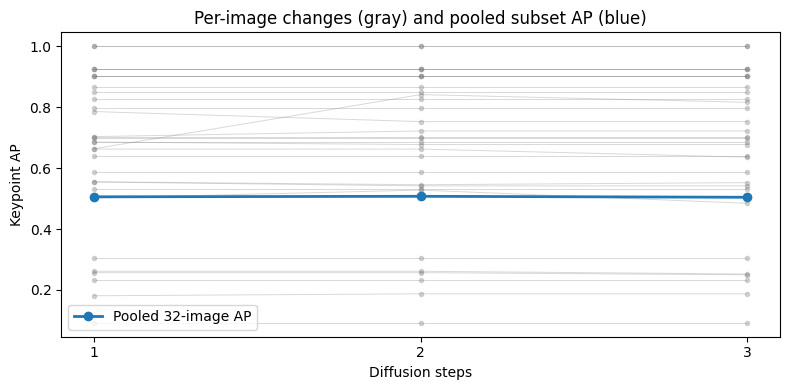

In [3]:
metrics = pd.DataFrame.from_dict(cache['metrics'], orient='index')
metrics.index.name = 'diffusion_steps'
display(metrics)
per_image = pd.DataFrame(cache['rows']).pivot(index='image_id', columns='steps', values='AP')
per_image.columns = [f'AP_S{step}' for step in per_image.columns]
per_image['S2_minus_S1'] = per_image['AP_S2'] - per_image['AP_S1']
per_image['S3_minus_S1'] = per_image['AP_S3'] - per_image['AP_S1']
with pd.option_context('display.max_rows', 32):
    display(per_image.sort_values(['AP_S1'], ascending=False))
selections = []
for steps in settings.steps:
    for cohort in ('best', 'worst'):
        for rank, image_id in enumerate(cache['rankings'][steps][cohort], 1):
            selections.append({'selected_at_S': steps, 'cohort': cohort, 'rank': rank,
                               'image_id': image_id, **per_image.loc[image_id].to_dict()})
selection_table = pd.DataFrame(selections)
display(selection_table)
print('Undefined scores by S:', {step: cache['rankings'][step]['undefined'] for step in settings.steps})
figure, axis = plt.subplots(figsize=(8, 4))
for image_id in per_image.index:
    axis.plot(settings.steps, [per_image.loc[image_id, f'AP_S{s}'] for s in settings.steps],
              color='gray', alpha=.3, marker='.', lw=.7)
axis.plot(settings.steps, metrics['AP'], color='tab:blue', marker='o', lw=2, label='Pooled 32-image AP')
axis.set(xlabel='Diffusion steps', ylabel='Keypoint AP', xticks=settings.steps,
         title='Per-image changes (gray) and pooled subset AP (blue)')
axis.legend(); figure.tight_layout()
display(figure); figure.savefig(FIGURES / 'performance.png', dpi=130); plt.close(figure)

## Best three and worst three, for every step count

Each column is one image; ground truth and final predictions occupy separate
rows. Joint colors follow the same convention throughout the notebook; white
rings identify labeled but occluded ground-truth joints. Low-confidence predictions
omitted from this gallery still contribute to AP.

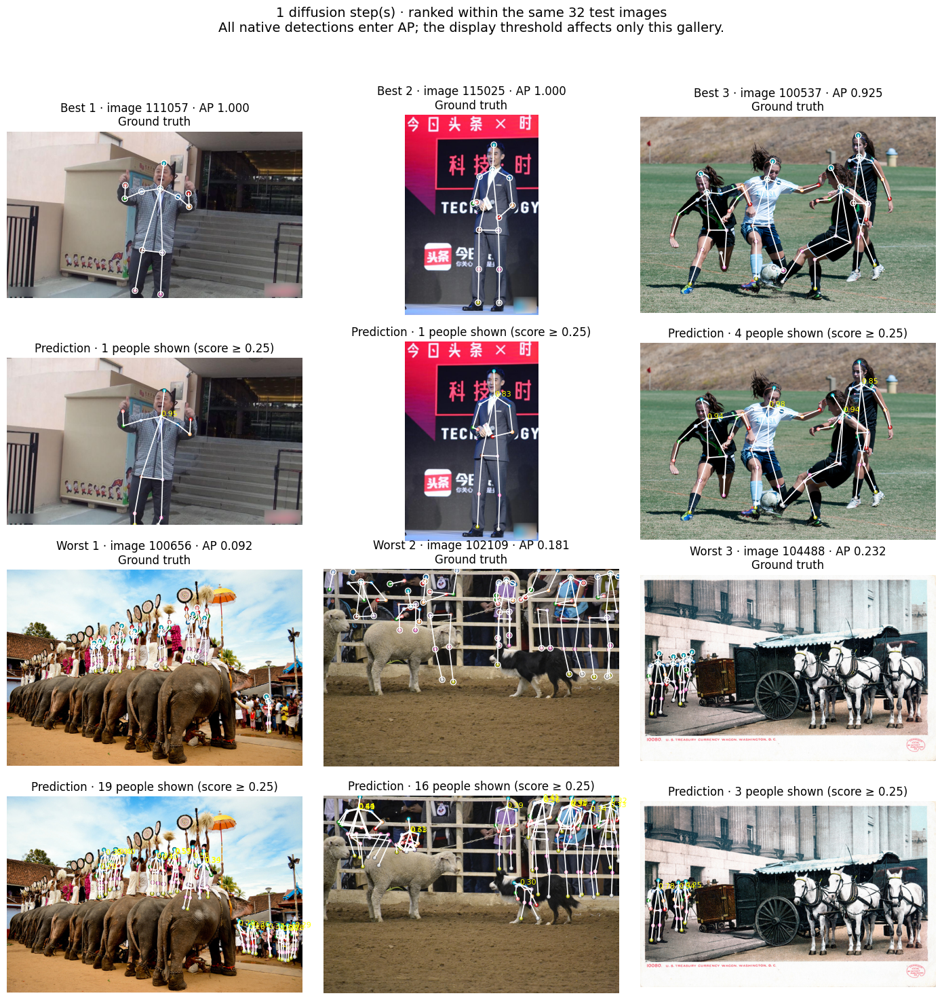

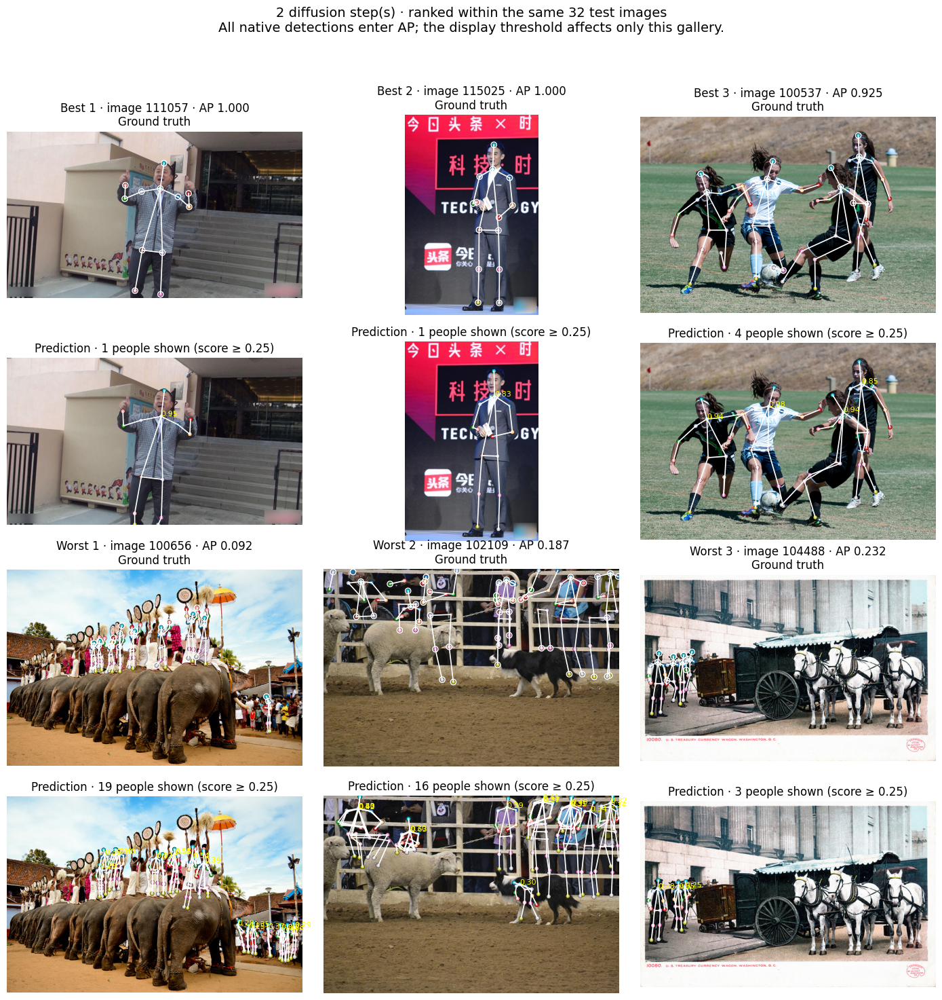

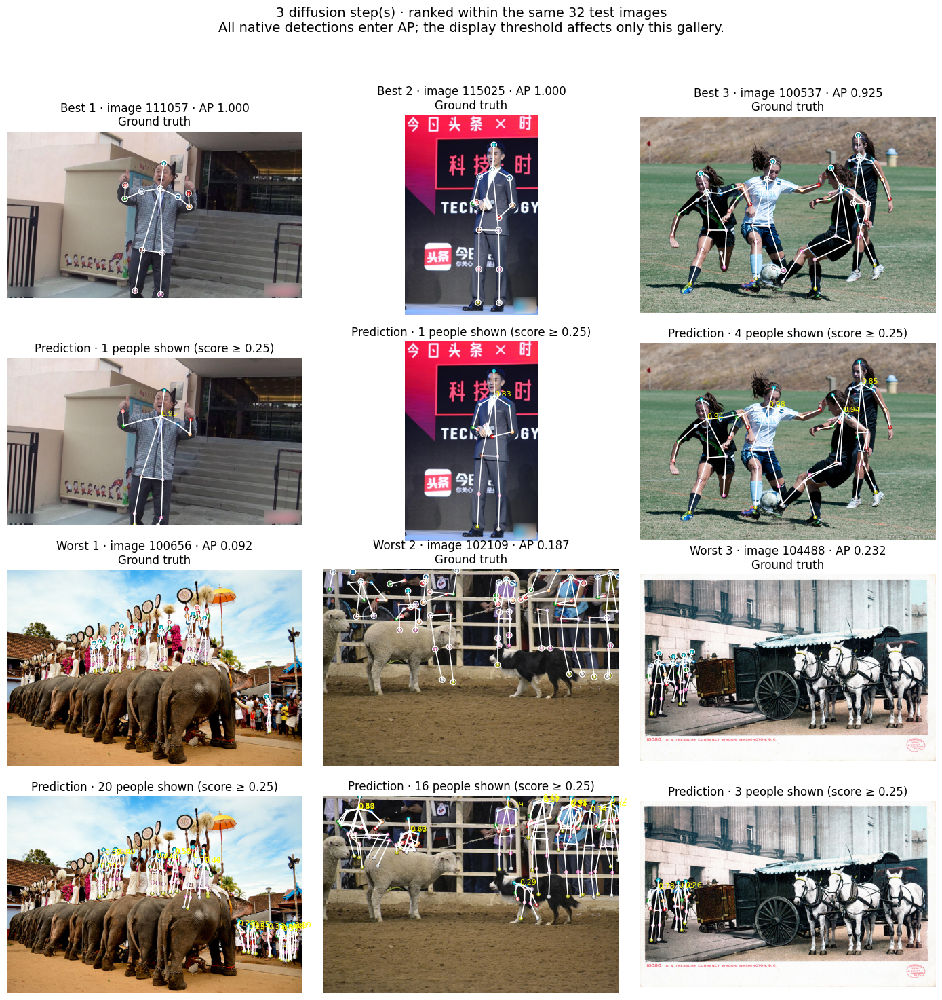

In [4]:
for steps in settings.steps:
    figure = gallery_figure(cache, steps, threshold=DISPLAY_SCORE_THRESHOLD)
    figure.savefig(FIGURES / f'gallery_s{steps}.png', dpi=130)
    display(figure)
    plt.close(figure)

## Diffusion state and each decoder layer

The default focus is the highest-confidence surviving person detection in the
selected image. This chooses a **local query group**, not a tracked person.
Box-to-joint expansion uses its captured top-k correspondence, so layer 1 plots
the actual ancestor box query. A group number can refer to different people in
different diffusion calls; the notebook makes no cross-call identity claim.

**Reference panels:** the geometry entering the decoder layer, including the
box center/extent and joint centers/extents. **Prediction panels:** the actual
native auxiliary/final heads after that layer, with class confidence. Predicted
joint locations never stand in for incoming references. Layer 1 has no joints.
Coordinates use image-normalized units (0/1 are the image boundaries) and are
converted to original image pixels. Incoming references can lie outside those
boundaries: their axes expand to show their actual coordinates and a count.
Prediction panels zoom to a common final-box crop; reference panels retain the
image context. State proposals are converted from diffusion units using scale=6.

Exported complete decoder/state figures for 18 selected image/settings under tmp/diffusionregpose_diffusion_inspection/figures.


### Best S=3 image 111057; focus group 0

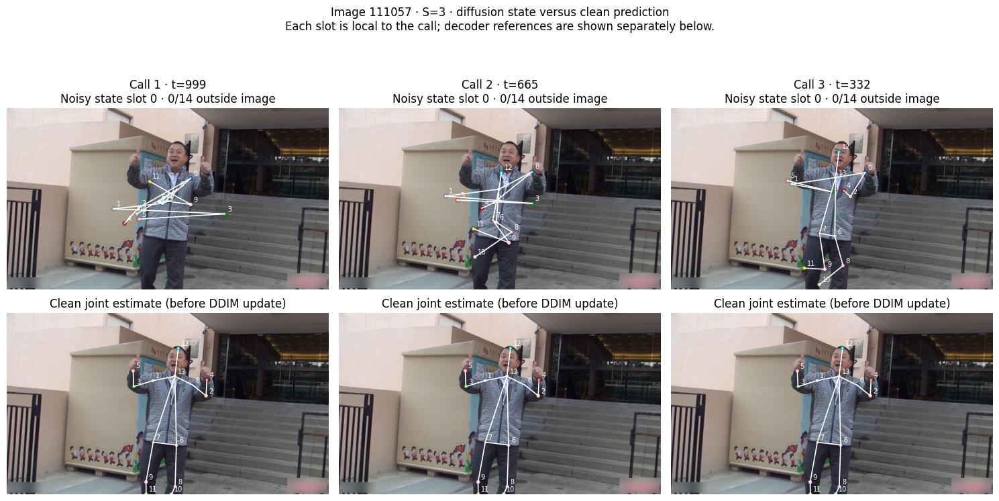

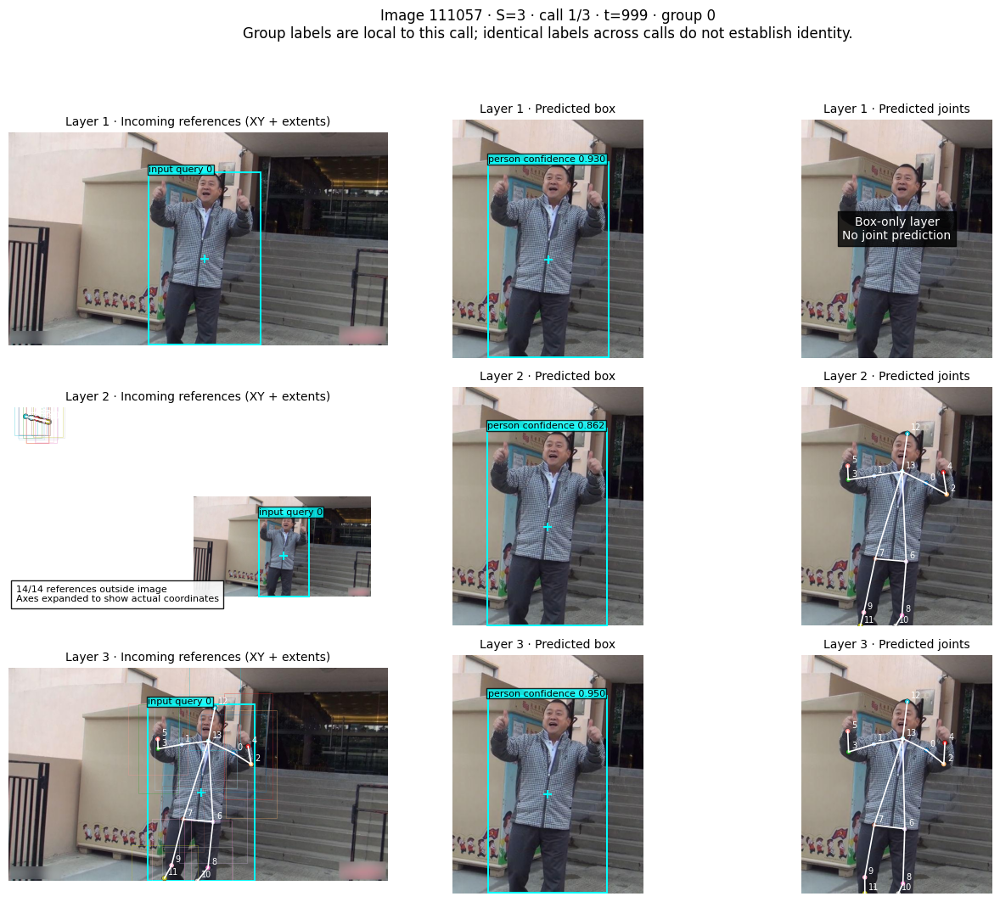

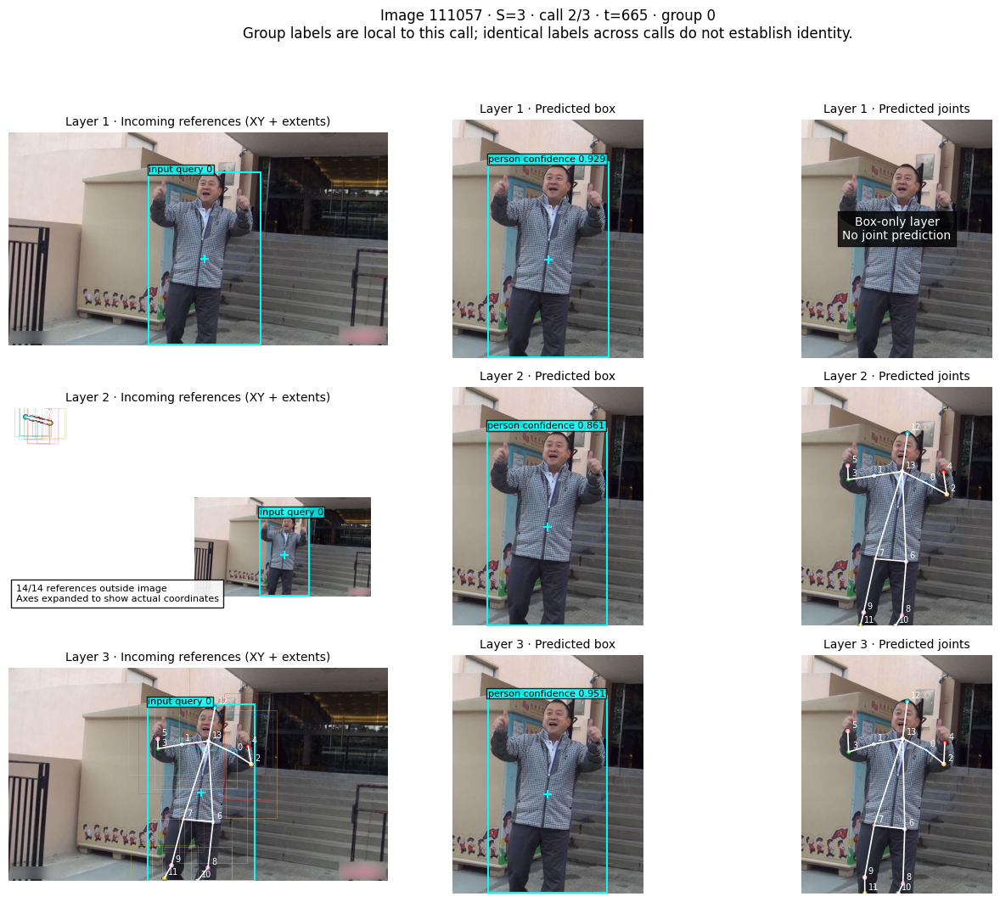

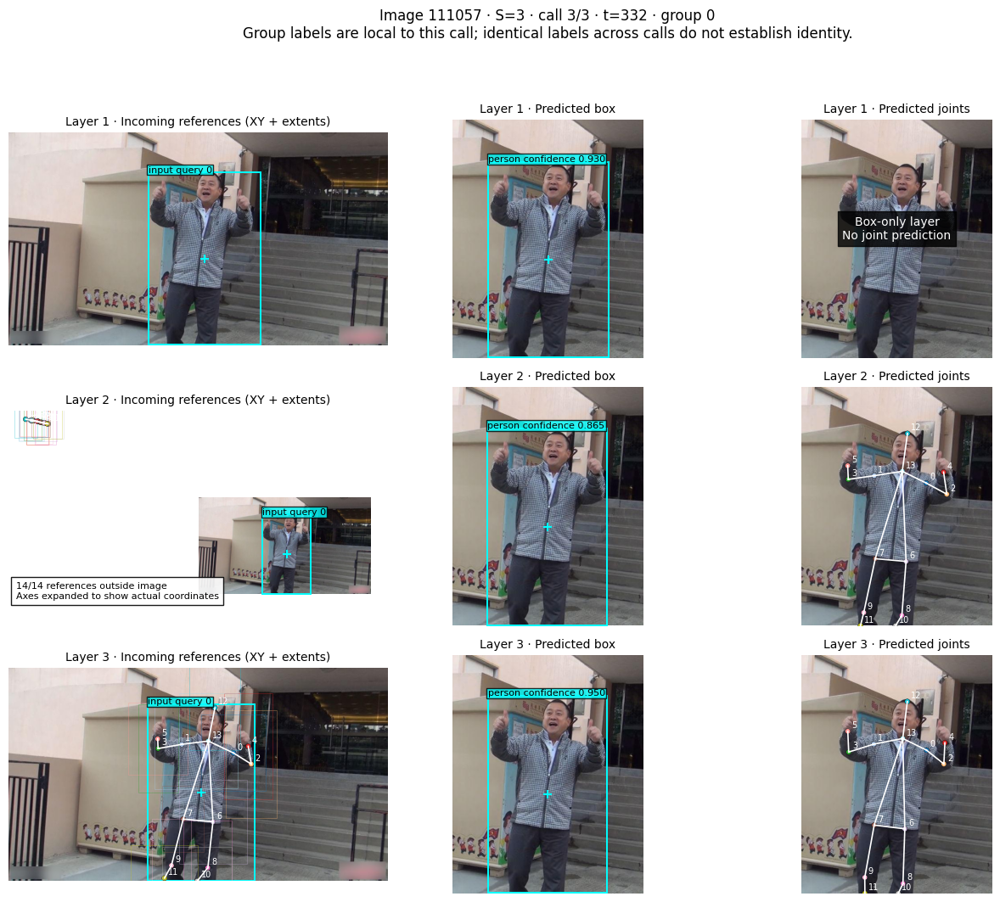

### Worst S=3 image 100656; focus group 1

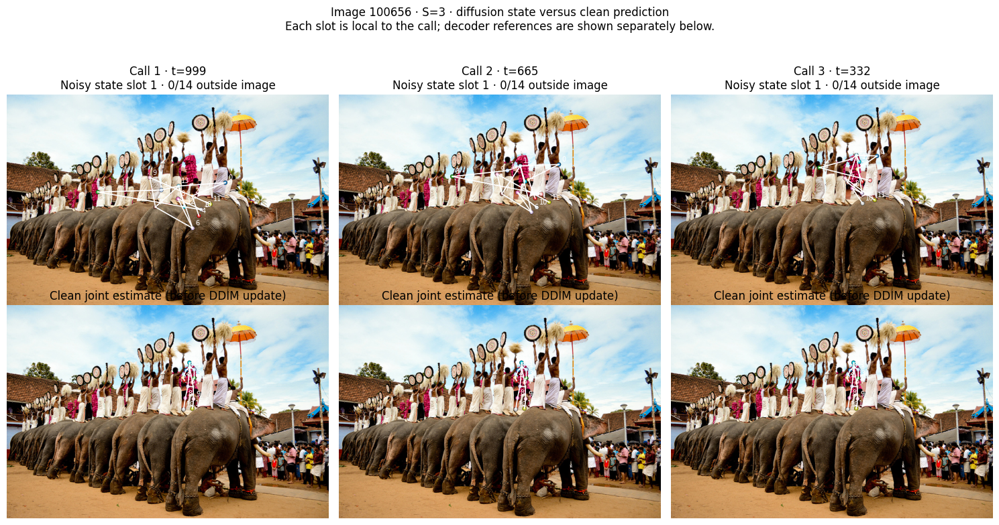

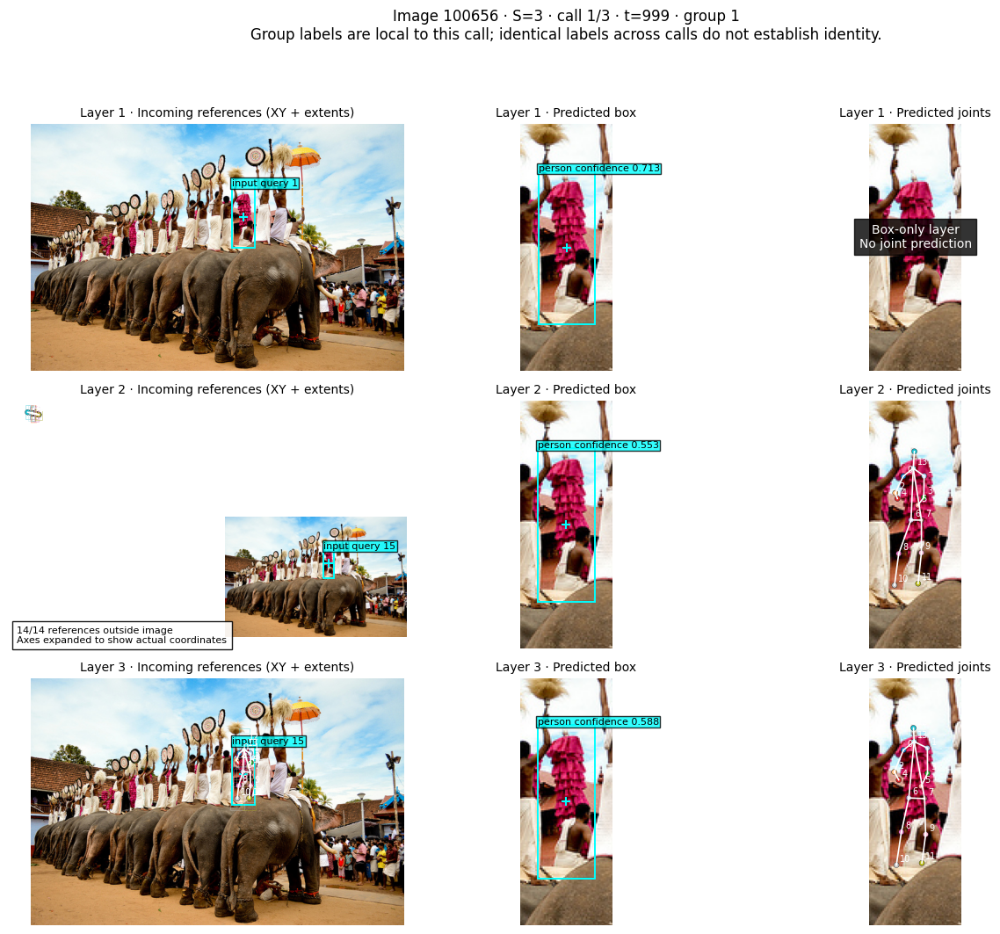

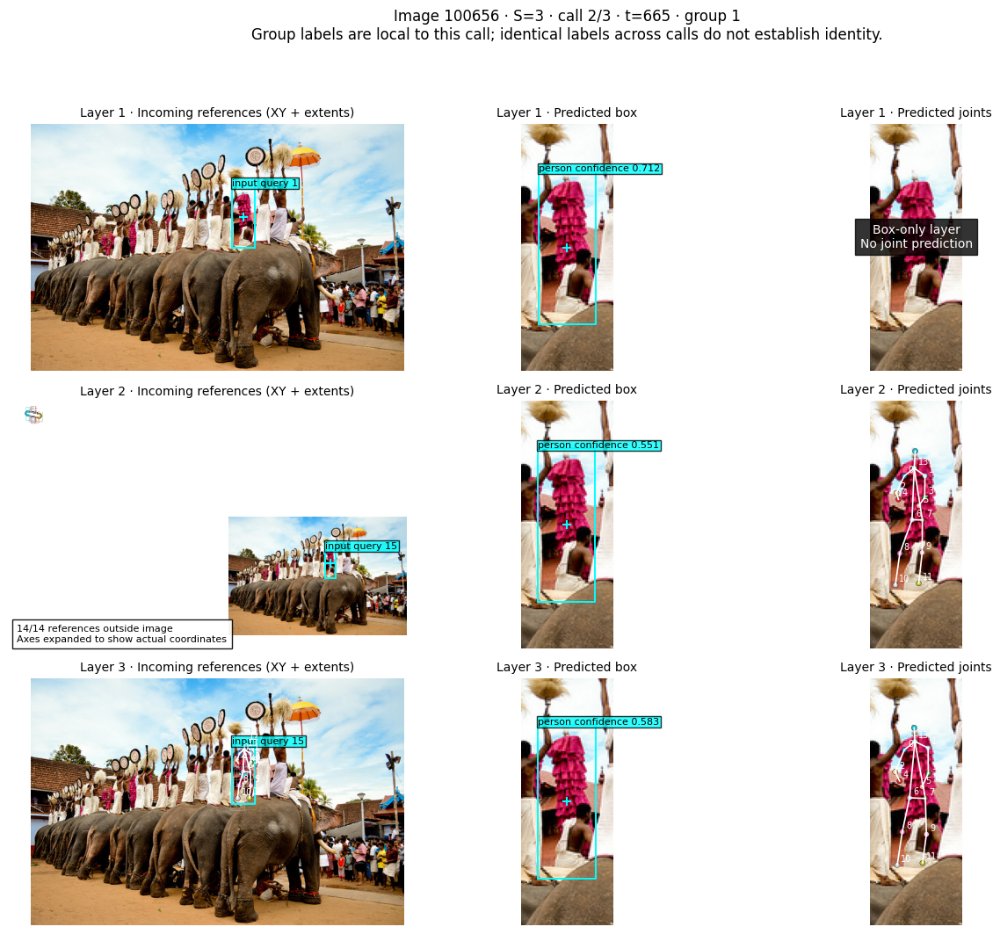

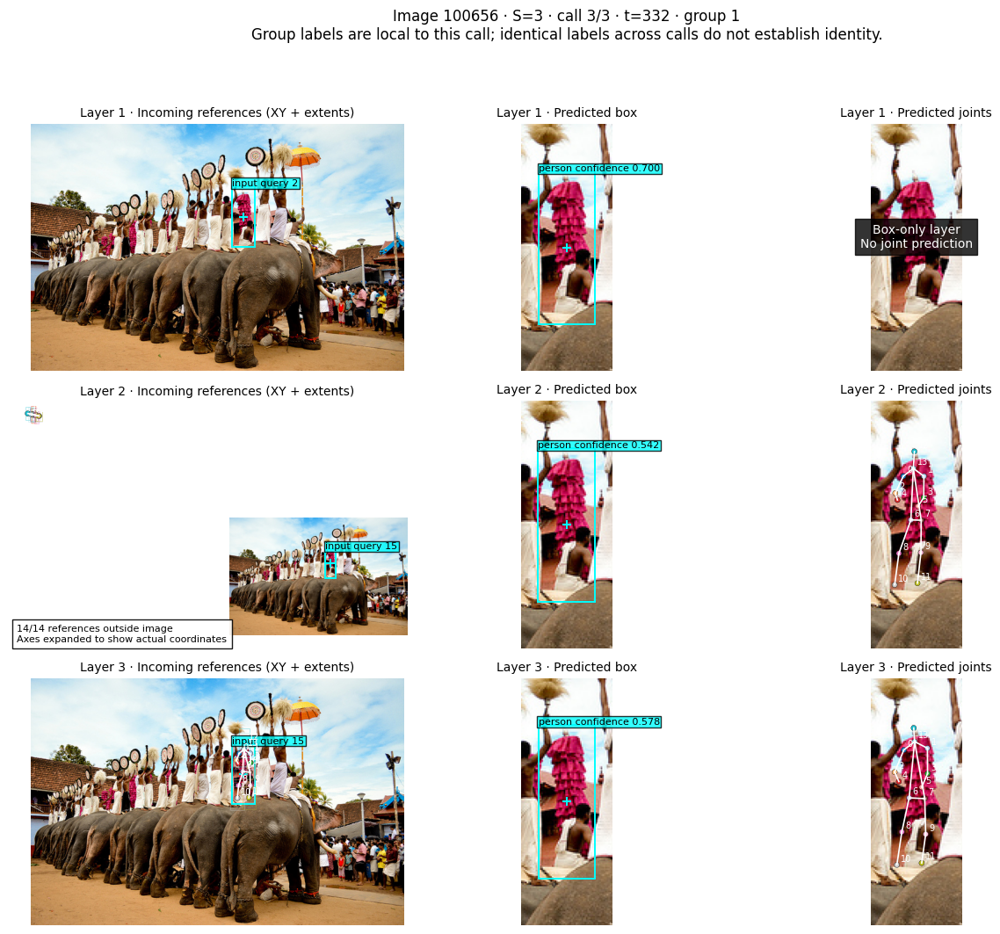

In [5]:
def focus_group(image_id, steps):
    result = cache['sweep'][(image_id, steps)]['result']
    people = (result['labels'] == 1).nonzero().flatten()
    if len(people):
        return int(result['query_ids'][people[0]])
    logits = cache['sweep'][(image_id, steps)]['prediction']['pred_logits'][0, :, 1]
    return int(logits.argmax())

def save_and_show(figure, filename, show=True):
    figure.savefig(FIGURES / filename, dpi=115)
    if show:
        display(figure)
    plt.close(figure)

# Export every selected best/worst case, with every call and every decoder layer.
exported = set()
for row in selection_table.to_dict('records'):
    image_id, steps = row['image_id'], row['selected_at_S']
    if (image_id, steps) in exported:
        continue
    exported.add((image_id, steps))
    group = focus_group(image_id, steps)
    save_and_show(proposal_figure(cache, image_id, steps, group),
                  f'state_{image_id}_s{steps}.png', show=False)
    for call in range(steps):
        save_and_show(geometry_figure(cache, image_id, steps, call, group),
                      f'geometry_{image_id}_s{steps}_call{call+1}.png', show=False)
print(f'Exported complete decoder/state figures for {len(exported)} selected image/settings under {FIGURES}.')

# Saved inline examples include both a best and a worst S=3 image and all their calls.
for cohort in ('best', 'worst'):
    image_id = cache['rankings'][3][cohort][0]
    group = focus_group(image_id, 3)
    display(Markdown(f'### {cohort.title()} S=3 image {image_id}; focus group {group}'))
    save_and_show(proposal_figure(cache, image_id, 3, group), f'state_{image_id}_s3.png')
    for call in range(3):
        save_and_show(geometry_figure(cache, image_id, 3, call, group),
                      f'geometry_{image_id}_s3_call{call+1}.png')

## Reference points, predicted offsets and sample strengths

**Start with the three clearly visible people below.** Each example shows the
selected person and predicted skeleton on the left, and attention for that
same person's left wrist on the right. The yellow ring identifies the predicted
joint; the green X marks the annotated joint; the white star is the incoming
reference point, which can differ from both.
The attention view retains the head/shoulders so the samples have body context.

These are the three best S=3 images from the fixed subset, using the highest
scoring surviving person detection in each image. Ground-truth association is
used only for the display crop, never to change predictions or evaluation.

- **White star:** the reference point.
- **Blue arrows:** predicted spatial offsets, from the reference to each sample.
- **Colored circles:** the four sample locations on that feature level.
- **Matching bars below:** each sample's attention strength, with its percentage.

Arrow thickness/opacity and dot size now reflect the original attention weight.
Weak samples remain visible but faint; distant points with less than 1% weight
should not look as strong as nearby samples carrying tens of percent.
These are sampling weights over encoded image features, not a pixel saliency map.

An audit of these three examples found that the first joint-refinement layer
samples outside even the image's bilinear interpolation support in all three
S=3 calls. Its joint samples therefore read zero image values before projection
bias. That is a real checkpoint behavior requiring investigation; successful
final predictions do not establish useful image reads at every earlier layer.
The opening figures show the final layer, whose strongest samples are more local.

Each opening example shows the feature level with the most attention for this
query/head. Sample colors match the legend and strength bars. Percentages sum
to 100% across all 16 samples (four levels × four samples) for this head; the
four displayed weights are not renormalized to make that level total 100%.
Arrows show offsets after the model's reference/feature scaling in image pixels.
No sample is moved onto the image boundary. If a selected layer has off-image
references, the view labels that explicitly and retains the person alongside.

The live controls below let you choose any saved image, call, layer, joint,
head and feature level. The opening examples use the final decoder layer;
intermediate-layer failures remain available in the controls.

### Structural query masks (separate from sample strength)

The self-attention mask is structural: **white = allowed; black = blocked**.
The box-only layer is unrestricted. In expanded layers, joint queries read their
own person group, while box queries can also read boxes from other groups.
A crop exposes this asymmetry. The mask is identical across heads and does not
measure learned query-query attention strength.

### Person example 1 · image 111057

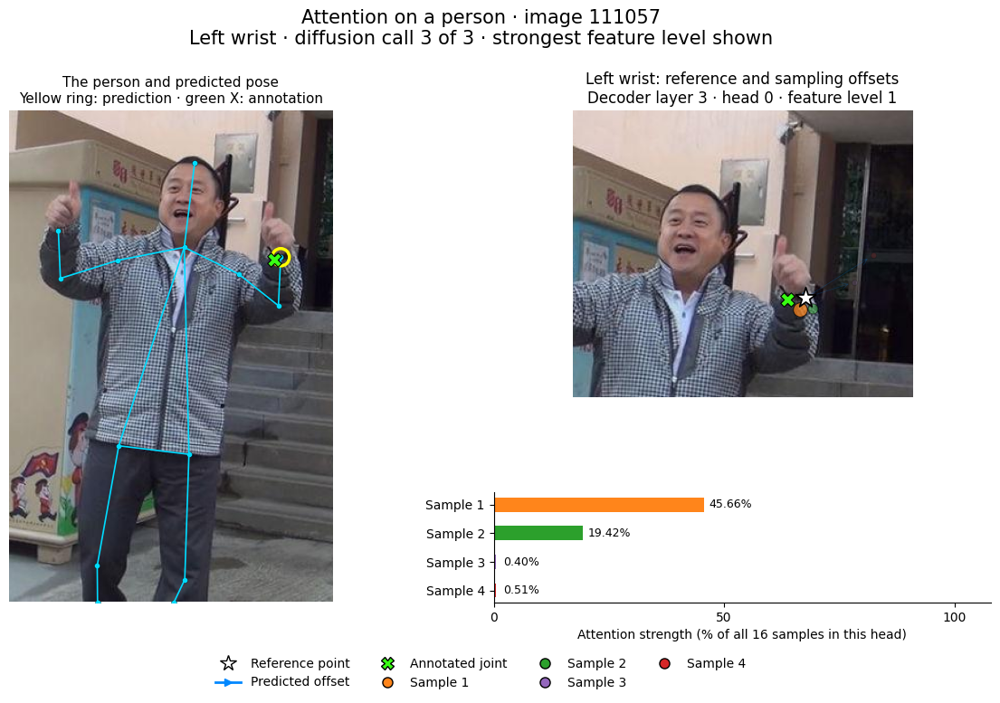

### Person example 2 · image 115025

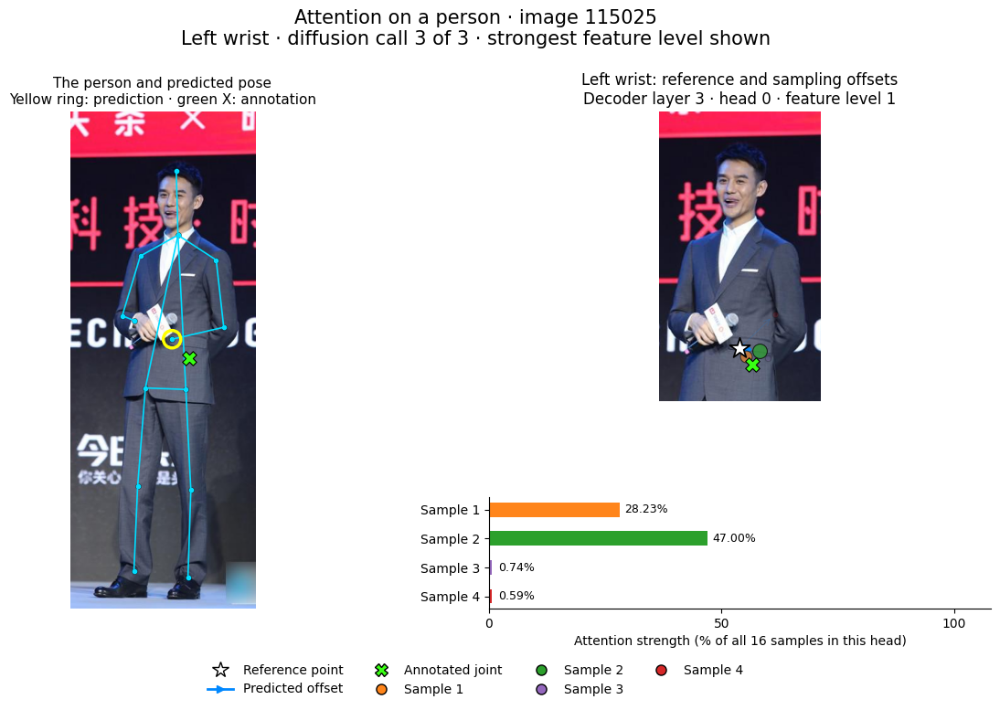

### Person example 3 · image 100537

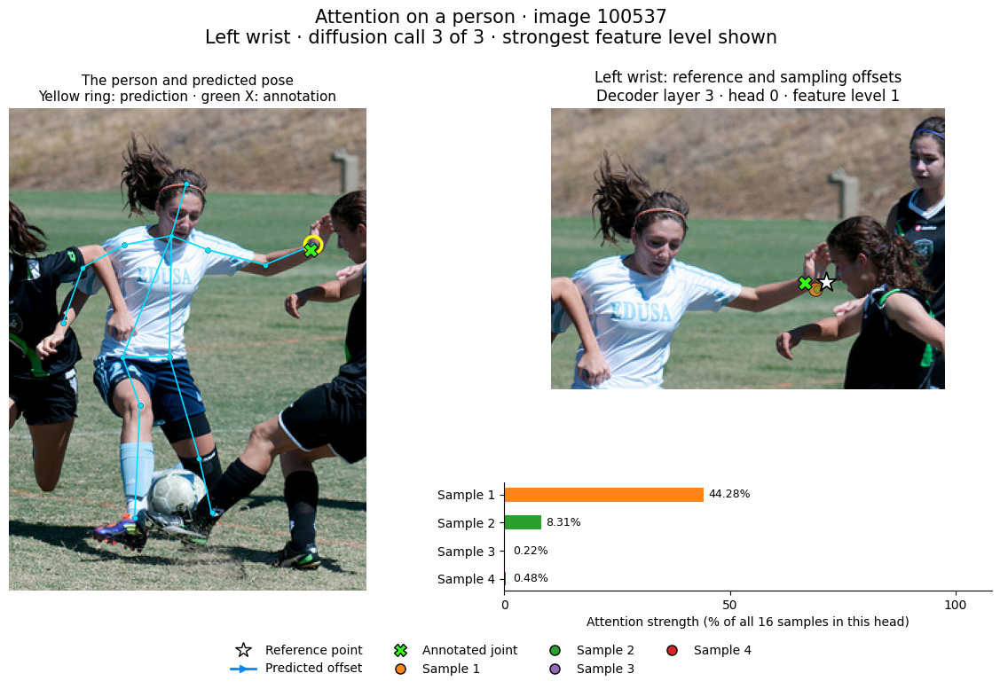

In [3]:
ATTENTION_IMAGE = cache['rankings'][3]['best'][0]
ATTENTION_GROUP = focus_group(ATTENTION_IMAGE, 3)
for example, image_id in enumerate(cache['rankings'][3]['best'], 1):
    group = focus_group(image_id, 3)
    display(Markdown(f'### Person example {example} · image {image_id}'))
    save_and_show(person_attention_figure(cache, image_id, 3, 2, group,
                                          joint=4, head=0, layer_index=2),
                  f'person_attention_{image_id}.png')
save_and_show(mask_figure(cache, ATTENTION_IMAGE, 3, 2, ATTENTION_GROUP), 'query_masks.png', show=False)

## Inspect any selected case, call, person group, joint and attention head

Use the controls and click **Update view** in a live Jupyter kernel. Every image in the union of the
best/worst cohorts is available at **all three S values**, so changing S keeps
the image fixed. Person groups are local to each call; choose a group by its
plotted geometry instead of assuming persistent identity. For a static viewer,
the figures above remain embedded and all selected-case decoder sheets are
exported under the figure directory. The function below also works directly.

In [4]:
def inspect_case(image_id, steps, call_number, person, view='Image attention', joint=4, head=0, layer=-1, feature=-1):
    call_index = min(call_number, steps) - 1
    if view == 'Geometry':
        figure = geometry_figure(cache, image_id, steps, call_index, person)
    elif view == 'Noisy state':
        figure = proposal_figure(cache, image_id, steps, person)
    elif view == 'Query mask':
        figure = mask_figure(cache, image_id, steps, call_index, person)
    else:
        figure = person_attention_figure(cache, image_id, steps, call_index, person,
                                         joint=None if joint == -1 else joint,
                                         head=head, layer_index=cache['decoder_layers']-1 if layer == -1 else layer,
                                         feature_level=None if feature == -1 else feature)
    display(figure)
    plt.close(figure)

import ipywidgets as widgets
example_ids = cache['rankings'][3]['best']
image_options = [(f'Example {i+1}: {image_id}', image_id) for i, image_id in enumerate(example_ids)]
image_options += [(f'Other case: {image_id}', image_id) for image_id in cache['selected'] if image_id not in example_ids]
image_control = widgets.Dropdown(options=image_options, value=ATTENTION_IMAGE, description='Image')
steps_control = widgets.Dropdown(options=list(settings.steps), value=3, description='Steps')
call_control = widgets.IntSlider(min=1, max=3, value=3, description='Call', continuous_update=False)
person_control = widgets.IntSlider(min=0, max=cache['num_groups']-1, value=ATTENTION_GROUP,
                                   description='Group', continuous_update=False)
view_control = widgets.Dropdown(options=['Geometry', 'Noisy state', 'Query mask', 'Image attention'],
                                value='Image attention', description='View')
joint_control = widgets.Dropdown(options=[('Box', -1)] + [(f'{i}: {name}', i) for i, name in enumerate(JOINT_NAMES)],
                                 value=4, description='Joint / box')
head_control = widgets.Dropdown(options=[(str(i), i) for i in range(cache['num_heads'])],
                                value=0, description='Head')
layer_control = widgets.Dropdown(options=[(f'Layer {i+1}', i) for i in range(cache['decoder_layers'])],
                                 value=cache['decoder_layers']-1, description='Layer')
feature_control = widgets.Dropdown(options=[('Strongest level', -1)]
                                   + [(f'Level {i+1}', i) for i in range(4)],
                                   value=-1, description='Feature')
def update_call_limit(change):
    call_control.max = change['new']
steps_control.observe(update_call_limit, names='value')
def update_person_focus(change):
    person_control.value = focus_group(image_control.value, steps_control.value)
image_control.observe(update_person_focus, names='value')
steps_control.observe(update_person_focus, names='value')
controls = widgets.VBox([widgets.HBox([image_control, steps_control, call_control]),
                         widgets.HBox([person_control, view_control]),
                         widgets.HBox([layer_control, joint_control, head_control]), feature_control])
update_button = widgets.Button(description='Update view', button_style='primary')
interactive = widgets.Output()
def update_view(button):
    with interactive:
        interactive.clear_output(wait=False)
        inspect_case(image_control.value, steps_control.value, call_control.value,
                     person_control.value, view_control.value, joint_control.value,
                     head_control.value, layer_control.value, feature_control.value)
update_button.on_click(update_view)
display(controls, update_button, interactive)
# Direct alternative: inspect_case(ATTENTION_IMAGE, 2, 1, ATTENTION_GROUP, 'Image attention', joint=4, head=0)

Button(button_style='primary', description='Update view', style=ButtonStyle())

Output()

## Verification and reading limits

Hooks observe detached values and are removed on exit. Selected-case replay
matches all raw final logits, boxes, keypoints and final diffusion state exactly.
This preserves the native attention kernel; requesting alternative returned
self-attention weights is unnecessary. Sampling points/weights are reconstructed
from the actual captured projection outputs and the native reference formula.
Unit tests independently cover the reconstruction, query mapping, ranking,
hook cleanup, prediction parity and empty/ignored-ground-truth evaluator behavior.

The displays establish what this checkpoint does on these images. Changes
across S may include different selected box proposals and group assignments;
they are not evidence of persistent person tracking or a full-test AP improvement.

In [5]:
assert len(cache['image_ids']) == len(set(cache['image_ids'])) == settings.sample_count
assert len(cache['sweep']) == settings.sample_count * len(settings.steps)
assert cache['verification']['selected_replay_exact']
trace_count = call_count = layer_count = 0
for image_id in cache['selected']:
    shared_source = None
    for steps in settings.steps:
        calls = load_trace(cache, image_id, steps)
        assert len(calls) == steps
        if shared_source is None:
            shared_source = calls[0]['state']
        else:
            torch.testing.assert_close(shared_source, calls[0]['state'], rtol=0, atol=0)
        trace_count += 1
        for call in calls:
            assert len(call['layers']) == cache['decoder_layers']
            call_count += 1
            for layer in call['layers']:
                layer_count += 1
                assert torch.isfinite(layer['locations']).all()
                assert torch.isfinite(layer['weights']).all()
                total = layer['weights'].sum((-1, -2))
                torch.testing.assert_close(total, torch.ones_like(total))
print({'evaluated_image_settings': len(cache['sweep']), 'traced_image_settings': trace_count,
       'traced_diffusion_calls': call_count, 'traced_decoder_layers': layer_count,
       'common_initial_noise_verified': True, 'exact_replay_verified': True})
print('Saved figures:', FIGURES.resolve())

{'evaluated_image_settings': 96, 'traced_image_settings': 18, 'traced_diffusion_calls': 36, 'traced_decoder_layers': 108, 'common_initial_noise_verified': True, 'exact_replay_verified': True}
Saved figures: /home/gasparyanartur/dev/pose-graph-diff/tmp/diffusionregpose_diffusion_inspection/figures


### Where the incoming references lie

This table counts actual reference centers in the selected-case traces. Box
stages count box queries; pose stages count joint queries only. Repeated
settings/calls are trace entries, not independent images. Out-of-image references
are observable model geometry, not a plotting conversion or a claim about their
causal effect on AP. The native refinement path can emit unrestricted coordinates.

In [6]:
reference_counts = {}
for image_id in cache['selected']:
    for steps in settings.steps:
        for call in load_trace(cache, image_id, steps):
            for layer_index, layer in enumerate(call['layers']):
                references = layer['references']
                if layer_index >= call['num_box_layers']:
                    keep = torch.arange(len(references)) % (call['num_joints']+1) != 0
                    references = references[keep]
                outside = ((references[:, :2] < 0) | (references[:, :2] > 1)).any(-1)
                counts = reference_counts.setdefault(layer_index+1, {'entries': 0, 'outside': 0})
                counts['entries'] += len(references)
                counts['outside'] += int(outside.sum())
reference_summary = pd.DataFrame.from_dict(reference_counts, orient='index')
reference_summary.index.name = 'decoder_layer'
reference_summary['outside_fraction'] = reference_summary['outside']/reference_summary['entries']
display(reference_summary)
print('Unique traced images:', len(cache['selected']))

,entries,outside,outside_fraction
decoder_layer,,,
1,7200,0,0.0
2,25200,25200,1.0
3,25200,0,0.0


Unique traced images: 6


## Does the diffusion state matter? Is the intermediate stage ineffective?

The frozen diagnostic uses these same 32 images and five native S=3 trajectories.
At each fixed image/time, changing the state moved final joints by only about
**0.01–0.02 pixels on average**. Incoming first-pose reference coordinates were
negative in both axes and collapsed to the same boundary in the coordinate
residual path. The raw references can still affect positional embeddings.

Decoder layer 2's **joint image read** contributes zero: removing its image
values while retaining the projection bias changes no predictions. But the
**whole layer is not ineffective**. Masking its joint self-attention and FFN
residual updates drops keypoint AP from 50.42 to 0. Removing only decoder
layer 3's joint image read drops AP to 18.45.

These masks replay individual calls at the original input state; they do not
rerun the whole masked diffusion trajectory. The combined removal also has
AP zero, so it cannot quantify downstream compensation. A graded weakening
of the first updates would be needed to avoid that floor.

Full methods, verified numbers and proposed follow-up:
[state sensitivity and masks](../../docs/reports/2026-10-24-image-information-report.md#native).

,Call 1 / t=999,Call 2 / t=665,Call 3 / t=332
Baseline,50.5718,50.6722,50.4237
First pose: joint image read off,50.5718,50.6722,50.4237
Final pose: joint image read off,18.2031,18.3252,18.4477
First pose: joint feature updates off,0.0000,0.0000,0.0000
First updates + final image read off,0.0000,0.0000,0.0000


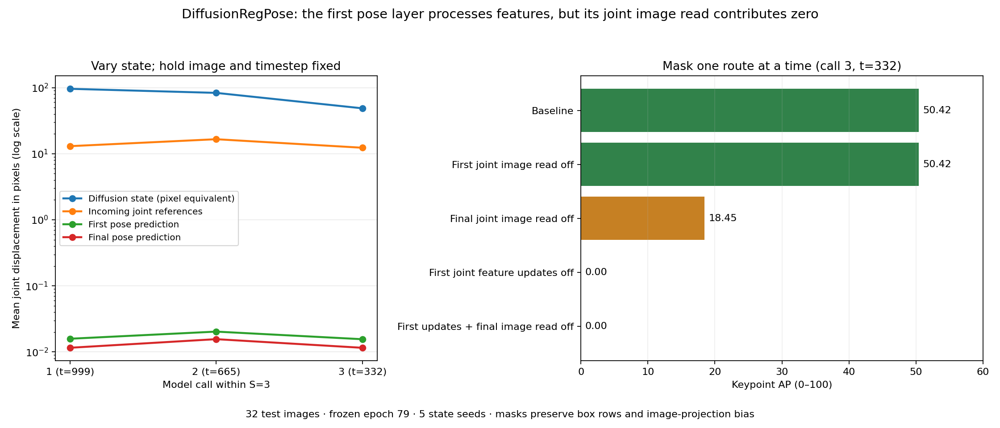

Raw and postprocessed cache parity: {'seed_zero_final_cache_exact': True, 'seed_zero_final_postprocessing_cache_exact': True, 'selected_box_slots_identical_at_fixed_time': True, 'first_joint_image_contribution_abs_max': 0.0, 'forward_calls': 864, 'hooks_removed': True}


In [7]:
import json
from IPython.display import Image

diagnostic_folder = ROOT / 'tmp/diffusionregpose_state_sensitivity_verified'
diagnostic_path = diagnostic_folder / 'results.json'
if diagnostic_path.exists():
    diagnostic = json.loads(diagnostic_path.read_text())
    conditions = {
        'seed0': 'Baseline',
        'first_joint_image_bias_only': 'First pose: joint image read off',
        'final_joint_image_bias_only': 'Final pose: joint image read off',
        'first_joint_feature_updates_off': 'First pose: joint feature updates off',
        'first_updates_off_and_final_image_bias_only': 'First updates + final image read off',
    }
    diagnostic_ap = pd.DataFrame({
        f'Call {call} / t={time}': {
            label: 100 * diagnostic['metrics'][f'{condition}_t{time}']['AP']
            for condition, label in conditions.items()
        } for call, time in enumerate((999, 665, 332), start=1)
    })
    display(diagnostic_ap.round(4))
    if (diagnostic_folder / 'summary.png').exists():
        display(Image(filename=str(diagnostic_folder / 'summary.png')))
    print('Raw and postprocessed cache parity:', diagnostic['verification'])
else:
    print('Run python -m scripts.investigation.diffusionregpose_inspection.state_sensitivity first.')